In [4]:
import pandas as pd
df = pd.read_csv("../data/train.csv")
print(df.shape)
df.head()

(594194, 21)


,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,3,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,4,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes


In [15]:
df.columns.tolist() # 查看数据集的列名

['id',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [6]:
df.info()  # 查看数据集的基本信息

<class 'pandas.DataFrame'>
RangeIndex: 594194 entries, 0 to 594193
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                594194 non-null  int64  
 1   gender            594194 non-null  str    
 2   SeniorCitizen     594194 non-null  int64  
 3   Partner           594194 non-null  str    
 4   Dependents        594194 non-null  str    
 5   tenure            594194 non-null  int64  
 6   PhoneService      594194 non-null  str    
 7   MultipleLines     594194 non-null  str    
 8   InternetService   594194 non-null  str    
 9   OnlineSecurity    594194 non-null  str    
 10  OnlineBackup      594194 non-null  str    
 11  DeviceProtection  594194 non-null  str    
 12  TechSupport       594194 non-null  str    
 13  StreamingTV       594194 non-null  str    
 14  StreamingMovies   594194 non-null  str    
 15  Contract          594194 non-null  str    
 16  PaperlessBilling  594194 non-nu

In [18]:
df["Churn"].value_counts()  # 统计Churn列中各个类别的数量
churn_rate = (df["Churn"] == "Yes").mean() # 计算客户流失率
print(f"客户流失率:{churn_rate:.2%}")

print("各字段缺失值数量：")
display(df.isna().sum() ) # 检查缺失值

print("完全重复的记录数：", df.duplicated().sum())  # 检查重复值
print("id 是否唯一：", df["id"].is_unique) # 检查id列是否唯一

客户流失率:22.52%
各字段缺失值数量：


id                  0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

完全重复的记录数： 0
id 是否唯一： True


In [19]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,594194.000000,594194.000000,594194.000000
mean,36.577258,65.866223,2494.377057
std,25.061922,31.067444,2353.916710
min,1.000000,18.250000,18.800000
25%,12.000000,29.900000,639.650000
50%,35.000000,74.100000,1433.650000
75%,62.000000,90.800000,4263.800000
max,72.000000,118.750000,8684.800000


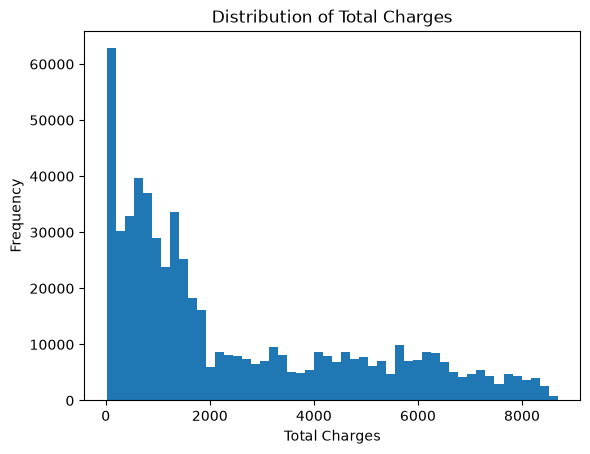

In [20]:
import matplotlib.pyplot as plt

plt.hist(df["TotalCharges"], bins=50)

plt.xlabel("Total Charges")
plt.ylabel("Frequency")
plt.title("Distribution of Total Charges")

plt.show()

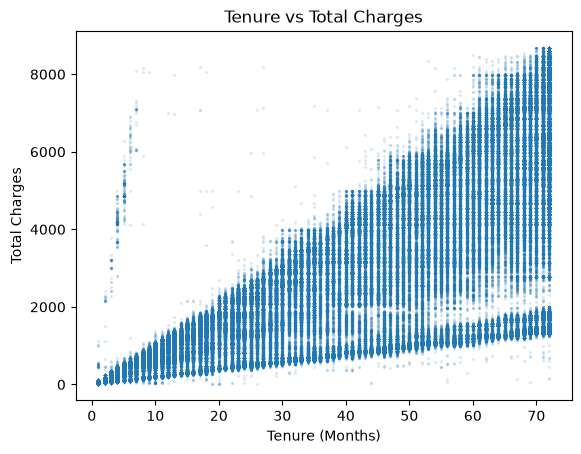

在网时长与累计费用的相关系数：0.7697


In [22]:
import matplotlib.pyplot as plt

# 绘制散点图
plt.scatter(df["tenure"], df["TotalCharges"], s=2, alpha=0.1)
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")
plt.title("Tenure vs Total Charges")
plt.show()

# 计算 Pearson 相关系数
r = df["tenure"].corr(df["TotalCharges"])
print(f"在网时长与累计费用的相关系数：{r:.4f}")

In [23]:

df["Contract"].value_counts()

Contract
Month-to-month    298918
Two year          186943
One year          108333
Name: count, dtype: int64

In [24]:
# 按合同类型计算客户流失率
churn_by_contract = (
    df.assign(ChurnFlag=df["Churn"] == "Yes")
      .groupby("Contract")["ChurnFlag"]
      .mean()
      .sort_values(ascending=False)
)

print((churn_by_contract * 100).round(2))

Contract
Month-to-month    42.05
One year           5.76
Two year           1.00
Name: ChurnFlag, dtype: float64


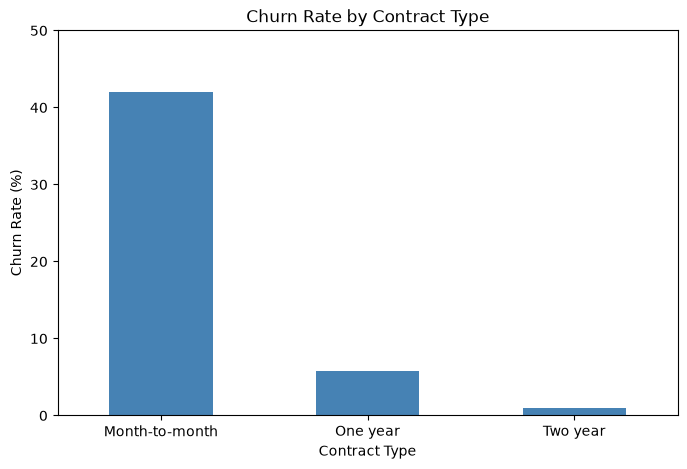

In [25]:
# 绘制不同合同类型的客户流失率
ax = (churn_by_contract * 100).plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)

plt.xticks(rotation=0)
plt.show()

In [26]:
# 按在网时长划分客户群体
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["1-12", "13-24", "25-48", "49-72"]
)

# 查看各组客户数量
df["TenureGroup"].value_counts().sort_index()

TenureGroup
1-12     152646
13-24     86024
25-48    127988
49-72    227536
Name: count, dtype: int64

In [27]:

# 分析不同在网时长、合同类型下的客户流失率
churn_table = (
    df.assign(ChurnFlag=df["Churn"] == "Yes")
      .groupby(["TenureGroup", "Contract"], observed=True)["ChurnFlag"]
      .agg(["mean", "size"])
)

churn_table["mean"] = (churn_table["mean"] * 100).round(2)

churn_table

mean    size
TenureGroup Contract                     
1-12        Month-to-month  51.85  145115
            One year         3.08    4712
            Two year         0.50    2819
13-24       Month-to-month  36.02   67458
            One year         2.15   12980
            Two year         0.16    5586
25-48       Month-to-month  32.21   62729
            One year         3.99   38765
            Two year         0.34   26494
49-72       Month-to-month  25.26   23616
            One year         8.24   51876
            Two year         1.15  152044

In [28]:
# 1. 计算标准权重：全体客户的在网时长分布
weights = df["TenureGroup"].value_counts(normalize=True).sort_index()

# 2. 提取各合同类型在不同在网时长组的流失率
rates = churn_table["mean"].unstack("Contract") / 100

# 3. 计算标准化流失率
standardized_rates = rates.mul(weights, axis=0).sum(axis=0)

# 4. 输出结果
print((standardized_rates * 100).round(2))

Contract
Month-to-month    35.15
One year           5.12
Two year           0.67
dtype: float64


In [29]:
# 直接从原始数据计算各层流失率（不提前四舍五入）
rates = (
    df.assign(ChurnFlag=df["Churn"] == "Yes")
      .groupby(["TenureGroup", "Contract"], observed=True)["ChurnFlag"]
      .mean()
      .unstack("Contract")
)

# 使用全体客户的在网时长分布作为标准权重
weights = df["TenureGroup"].value_counts(normalize=True).sort_index()

# 计算标准化流失率
standardized_rates = rates.mul(weights, axis=0).sum(axis=0)

# 比较原始流失率和标准化流失率
original_rates = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean()
)

comparison = pd.DataFrame({
    "Original (%)": original_rates * 100,
    "Standardized (%)": standardized_rates * 100
})

comparison.round(2)

,Original (%),Standardized (%)
Contract,,
Month-to-month,42.05,35.15
One year,5.76,5.11
Two year,1.00,0.67


In [30]:
# 按每月费用的四分位数划分客户群体
df["ChargeGroup"] = pd.qcut(
    df["MonthlyCharges"],
    q=4,
    duplicates="drop"
)

# 查看各组的费用范围和客户数量
df.groupby("ChargeGroup", observed=True)["MonthlyCharges"].agg(
    ["min", "max", "count"]
)

,min,max,count
ChargeGroup,,,
"(18.249, 29.9]",18.25,29.90,148686
"(29.9, 74.1]",29.95,74.10,148448
"(74.1, 90.8]",74.15,90.80,149070
"(90.8, 118.75]",90.85,118.75,147990


In [31]:
# 计算不同费用组的客户流失率
churn_by_charge = (
    df.assign(ChurnFlag=df["Churn"] == "Yes")
      .groupby("ChargeGroup", observed=True)["ChurnFlag"]
      .agg(["mean", "size"])
)

# 转换为百分比
churn_by_charge["mean"] *= 100

# 展示结果
churn_by_charge.round(2)

,mean,size
ChargeGroup,,
"(18.249, 29.9]",3.06,148686
"(29.9, 74.1]",18.92,148448
"(74.1, 90.8]",35.15,149070
"(90.8, 118.75]",32.96,147990


In [32]:
# 查看互联网服务类型及客户数量
df["InternetService"].value_counts()

InternetService
Fiber optic    272386
DSL            181081
No             140727
Name: count, dtype: int64

In [33]:
# 不同费用组的互联网服务类型构成
service_distribution = pd.crosstab(
    df["ChargeGroup"],
    df["InternetService"],
    normalize="index"
)

(service_distribution * 100).round(2)

InternetService,DSL,Fiber optic,No
ChargeGroup,,,
"(18.249, 29.9]",5.28,0.08,94.64
"(29.9, 74.1]",81.98,18.02,0.01
"(74.1, 90.8]",32.38,67.62,0.00
"(90.8, 118.75]",2.21,97.79,0.00


In [34]:
# 按费用组和互联网服务类型计算流失率
churn_by_service = (
    df.assign(ChurnFlag=df["Churn"] == "Yes")
      .groupby(
          ["ChargeGroup", "InternetService"],
          observed=True
      )["ChurnFlag"]
      .agg(["mean", "size"])
)

# 转换为百分比
churn_by_service["mean"] *= 100

churn_by_service.round(2)

mean    size
ChargeGroup    InternetService               
(18.249, 29.9] DSL              31.48    7850
               Fiber optic      58.82     119
               No                1.43  140717
(29.9, 74.1]   DSL              12.49  121695
               Fiber optic      48.17   26743
               No                0.00      10
(74.1, 90.8]   DSL               1.98   48271
               Fiber optic      51.03  100799
(90.8, 118.75] DSL               1.04    3265
               Fiber optic      33.68  144725